In [ ]:
# Load the raw files

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
SOURCES = ["MODIS_SP", "VIIRS_SNPP_SP", "VIIRS_NOAA20_SP"]


def load(source: str) -> pd.DataFrame:
    frames = [pd.read_csv(f) for f in sorted(RAW.glob(f"{source}_2018-*.csv"))]
    frames = [f for f in frames if len(f)]  # skip header-only (no fires) chunks
    df = pd.concat(frames, ignore_index=True)  # stack the tables and renumber
    df["source"] = source  # record which dataset each row came from
    return df


raw = {s: load(s) for s in SOURCES}
{s: len(d) for s, d in raw.items()}

Matplotlib is building the font cache; this may take a moment.


{'MODIS_SP': 1406, 'VIIRS_SNPP_SP': 9071, 'VIIRS_NOAA20_SP': 8657}

In [ ]:
# One shared table for all sources

# Same meaning, different names per sensor
# Measure brightness in Kelvin
rename = {
    "brightness": "bt_fire",
    "bright_t31": "bt_bg",
    "bright_ti4": "bt_fire",
    "bright_ti5": "bt_bg",
}

# Stack and rename columns in each table
df = pd.concat([d.rename(columns=rename) for d in raw.values()], ignore_index=True)
df["family"] = df["source"].str.split("_").str[0]  # MODIS or VIIRS
# Date is text in the CSV --> make it a real date
df["acq_date"] = pd.to_datetime(df["acq_date"])
df["month"] = df["acq_date"].dt.month

# FIRMS types: 0 = presumed vegetation fire, 1 = volcano, 2 = other static land source
# 3 = offshjore
df.groupby(["source", "type"]).size().unstack(fill_value=0)

type,0,2,3
source,,,
MODIS_SP,1328,37,41
VIIRS_NOAA20_SP,3865,2657,2135
VIIRS_SNPP_SP,4044,2793,2234


MODIS is almsot all type 0, probably because its 1km pixels are less sensitive to small hot spots, and its static flagging is weaker.

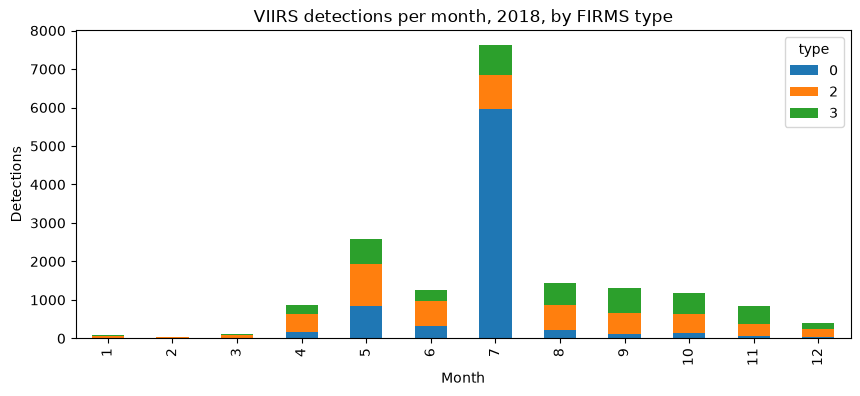

In [ ]:
# When does it happen

viirs = df[df["family"] == "VIIRS"]  # Boolean filtering. df keeps the True rows

ax = (
    viirs.groupby(["month", "type"])
    .size()
    .unstack(fill_value=0)
    .plot(kind="bar", stacked=True, figsize=(10, 4))
)
ax.set_title("VIIRS detections per month, 2018, by FIRMS type")
ax.set_xlabel("Month")
ax.set_ylabel("Detections");

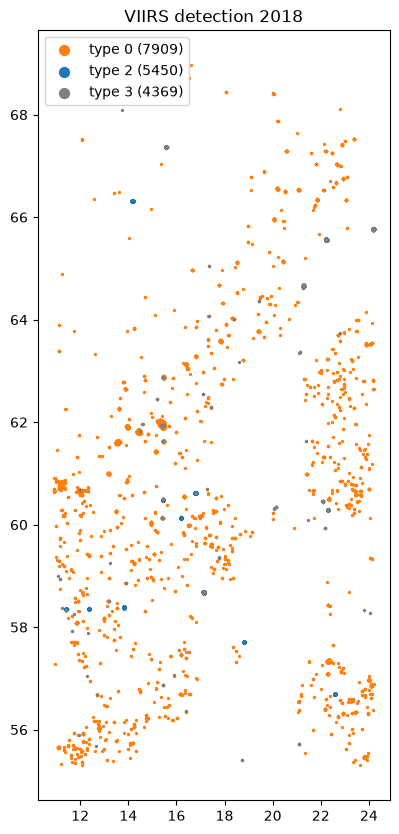

In [ ]:
# Where does it happen

fig, ax = plt.subplots(figsize=(6, 10))

for t, colour in [(0, "tab:orange"), (2, "tab:blue"), (3, "tab:gray")]:
    d = viirs[viirs["type"] == t]
    ax.scatter(d["longitude"], d["latitude"], s=2, c=colour, label=f"type {t} ({len(d)})")

# One degree of longitude is shorter than one of latitude this far north
ax.set_aspect(1 / np.cos(np.radians(62)))
ax.set_title("VIIRS detection 2018")
ax.legend(markerscale=5);


## Findings of this data exploration:

**Data.** 2018 contains 19,134 detections in the Sweden bounding box: MODIS 1,406, VIIRS SNPP 9,071, VIIRS NOAA-20 8,657. NOAA-20's archive starts in April 2018, so January–March has only one VIIRS satellite. Any jump in April is partly a jump in satellites, not in fires.

**1. Over half of VIIRS detections are not fires.** FIRMS labels 10,000+ of 17,700 VIIRS detections as static land sources (type 2) or offshore (type 3).

**2. "Offshore" is really coastal industry.** The most active type-3 locations are coastal steelworks and smelters (Luleå, Tornio, Rönnskär). At Oxelösund, two neighbouring pixels from the same overpass got type 2 and type 3. Types 2 and 3 should be treated together as "static".

**3. Recurrence separates factories from fires.** The busiest locations are detected on 70–234 different days, spread over 8–12 months. A forest fire lasts days to weeks.

**4. Factories are seen at night.** 84% of type-2 detections are at night, compared with about 50% for presumed fires.

**5. MODIS misses most factories and mislabels some.** Of the 15 most active VIIRS locations, MODIS detects only 6, and on far fewer days (5–19 vs 73–234). At two sites MODIS labels the detections as vegetation fires (type 0), so in MODIS-only years (2000–2011) some factories would be counted as fires.

**6. The bounding box includes neighbouring countries.** Finland, Norway, Denmark and the Baltic states are in the raw data. Results must be clipped to Sweden's border.

**Follow up:** build a list of static sites from VIIRS recurrence, apply it to both sensors, and use multi-year recurrence for the MODIS-only years.



